### 다중분류

- 손글씨 분류   
  - total : 70000개
  - 학습set : 60000개
  - test set : 10000개
  - image shape : 28x28
  - class 10개 : 0~9











In [46]:
import torch
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader
import os
os.makedirs('results', exist_ok=True)

In [47]:
# 내 구글드라이브와 연동
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [48]:
# 장치 선택
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cuda


In [49]:
# 데이터 저장하기
transform = transforms.ToTensor()
train_DS = datasets.MNIST(root = '/content/drive/MyDrive/Colab Notebooks/data'
                        , train=True, download=True, transform=transform)
test_DS = datasets.MNIST(root = '/content/drive/MyDrive/Colab Notebooks/data'
                        , train=False, download=True, transform=transform)

In [50]:
print(train_DS)
print(test_DS)

Dataset MNIST
    Number of datapoints: 60000
    Root location: /content/drive/MyDrive/Colab Notebooks/data
    Split: Train
    StandardTransform
Transform: ToTensor()
Dataset MNIST
    Number of datapoints: 10000
    Root location: /content/drive/MyDrive/Colab Notebooks/data
    Split: Test
    StandardTransform
Transform: ToTensor()


In [51]:
train_DS.classes

['0 - zero',
 '1 - one',
 '2 - two',
 '3 - three',
 '4 - four',
 '5 - five',
 '6 - six',
 '7 - seven',
 '8 - eight',
 '9 - nine']

In [52]:
train_DS.class_to_idx

{'0 - zero': 0,
 '1 - one': 1,
 '2 - two': 2,
 '3 - three': 3,
 '4 - four': 4,
 '5 - five': 5,
 '6 - six': 6,
 '7 - seven': 7,
 '8 - eight': 8,
 '9 - nine': 9}

In [53]:
train_DS.data.shape

torch.Size([60000, 28, 28])

In [54]:
train_DS.data[0]

tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,
          18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   

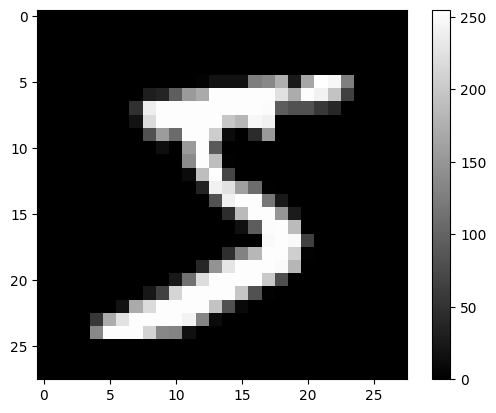

In [55]:
plt.imshow(train_DS.data[0], cmap='gray')
plt.colorbar()

In [56]:
print(train_DS.targets)
print(train_DS.targets.shape)

tensor([5, 0, 4,  ..., 5, 6, 8])
torch.Size([60000])


### DataLoader

In [57]:
BATCH_SIZE = 32
train_DL = DataLoader(train_DS, batch_size=BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=True)

In [58]:
x_batch, y_batch = next(iter(train_DL))

# 원본데이터
print(type(train_DS.data))
print(train_DS.data.shape)
print(train_DS.data.dtype)
print(train_DS.data[0].shape)

# batch데이터
print(type(x_batch))
print(x_batch.shape)
print(x_batch.dtype)
print(x_batch[0].shape)

<class 'torch.Tensor'>
torch.Size([60000, 28, 28])
torch.uint8
torch.Size([28, 28])
<class 'torch.Tensor'>
torch.Size([32, 1, 28, 28])
torch.float32
torch.Size([1, 28, 28])


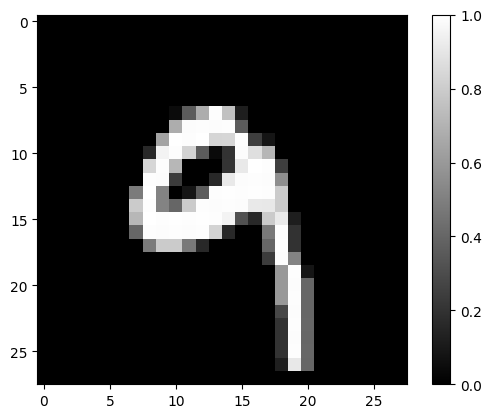

In [59]:
plt.imshow(x_batch[0].permute(1,2,0), cmap='gray')
plt.colorbar()

### Model 만들기

In [60]:
from torch import nn

class MLP(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(nn.Linear(28*28, 100),
                                nn.ReLU(),
                                nn.Linear(100, 10))

  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

In [61]:
x_batch, _ = next(iter(train_DL))
print(x_batch.shape)

flat_images = torch.flatten(x_batch)
print(flat_images.shape)

flat_images2 = torch.flatten(x_batch, start_dim=1)
print(flat_images2.shape)

torch.Size([32, 1, 28, 28])
torch.Size([25088])
torch.Size([32, 784])


In [62]:
model = MLP().to(DEVICE)
print(model)

x_batch, _ = next(iter(train_DL))
print(x_batch.shape)

model.eval()
with torch.no_grad():
  print(model(x_batch.to(DEVICE)).shape)

MLP(
  (linear): Sequential(
    (0): Linear(in_features=784, out_features=100, bias=True)
    (1): ReLU()
    (2): Linear(in_features=100, out_features=10, bias=True)
  )
)
torch.Size([32, 1, 28, 28])
torch.Size([32, 10])


In [65]:
from torch import optim

LR = 1e-3
EPOCH = 5
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

def Train(model, train_DL, criterion, optimizer, EPOCH):
  loss_history=[]
  NoT = len(train_DL.dataset)

  model.train()
  for ep in range(EPOCH):
    rloss = 0
    for x_batch, y_batch in train_DL:
      x_batch = x_batch.to(DEVICE)
      y_batch = y_batch.to(DEVICE)

      y_hat = model(x_batch)

      loss = criterion(y_hat, y_batch)

      optimizer.zero_grad()
      loss.backward()
      optimizer.step()

      loss_b = loss.item() * x_batch.shape[0]
      rloss += loss_b

    loss_e = rloss/ NoT
    loss_history += [loss_e]
    print(f'Epoch : {ep+1}, train loss : {loss_e:.3f}')
    print('-' * 20)

  return loss_history

Epoch : 1, train loss : 0.048
--------------------
Epoch : 2, train loss : 0.038
--------------------
Epoch : 3, train loss : 0.033
--------------------
Epoch : 4, train loss : 0.027
--------------------
Epoch : 5, train loss : 0.022
--------------------


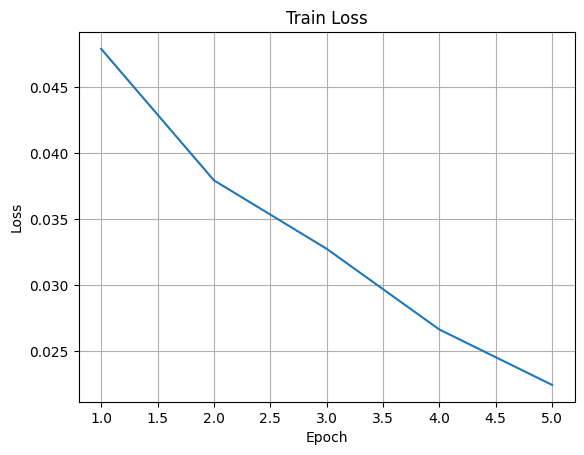

In [66]:
loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

plt.plot(range(1, EPOCH+1), loss_history)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train Loss')
plt.grid()

### ▶ 모델저장하고 불러오기

In [67]:
save_dir = '/content/dirve/MyDrive/Colab Notebooks/results'
os.makedirs(save_dir, exist_ok=True)
save_model_path = f'{save_dir}/MLP.pt'
torch.save(model.state_dict(), save_model_path)

In [68]:
load_model = MLP().to(DEVICE)
load_model.load_state_dict(torch.load(save_model_path, map_location=DEVICE))

<All keys matched successfully>

### ▶ 모델 테스트

In [71]:
model.eval()

with torch.no_grad():
  rcorrect = 0    # 잘 분류한거 누적으로 넣는 변수
  for x_batch, y_batch in test_DL :
    x_batch = x_batch.to(DEVICE)
    y_batch = y_batch.to(DEVICE)

    y_hat = model(x_batch)

    pred = y_hat.argmax(dim=1)
    print(y_hat.shape)
    print(pred)

    corrects_b = torch.sum(pred == y_batch).item()
    rcorrect += corrects_b

  accuracy_e = rcorrect/len(test_DL.dataset) * 100

print(f'Test accuracy : {rcorrect} / {len(test_DL.dataset)} ({accuracy_e:.1f} %)')







torch.Size([32, 10])
tensor([7, 4, 1, 6, 3, 6, 8, 9, 5, 7, 3, 5, 1, 5, 9, 6, 2, 7, 9, 6, 0, 6, 5, 8,
        1, 6, 8, 6, 3, 6, 0, 9], device='cuda:0')
torch.Size([32, 10])
tensor([8, 1, 7, 3, 6, 5, 4, 3, 1, 7, 7, 4, 1, 2, 0, 5, 6, 0, 5, 1, 5, 9, 6, 3,
        1, 2, 0, 0, 2, 1, 0, 1], device='cuda:0')
torch.Size([32, 10])
tensor([1, 9, 7, 8, 7, 6, 8, 9, 2, 3, 9, 5, 3, 7, 6, 9, 9, 2, 6, 7, 7, 1, 9, 7,
        8, 0, 6, 6, 2, 7, 0, 0], device='cuda:0')
torch.Size([32, 10])
tensor([2, 0, 3, 6, 8, 0, 0, 8, 3, 5, 0, 6, 8, 3, 2, 3, 8, 6, 7, 8, 9, 4, 9, 1,
        9, 6, 2, 3, 4, 9, 7, 7], device='cuda:0')
torch.Size([32, 10])
tensor([2, 9, 3, 3, 6, 8, 1, 0, 4, 8, 4, 2, 6, 9, 7, 7, 2, 6, 5, 0, 2, 9, 6, 6,
        8, 9, 3, 8, 7, 9, 3, 7], device='cuda:0')
torch.Size([32, 10])
tensor([6, 1, 7, 0, 1, 0, 3, 8, 6, 9, 1, 3, 4, 5, 5, 1, 8, 7, 5, 1, 9, 5, 1, 4,
        1, 2, 0, 9, 5, 1, 9, 9], device='cuda:0')
torch.Size([32, 10])
tensor([9, 4, 4, 7, 8, 5, 5, 7, 7, 3, 0, 7, 6, 2, 2, 9, 0, 7, 1, 2, 2, 0,

- .to(DEVICE)
  - GPU와 CPU는 다른 메모리 사용
  - DataLoader에서 데이터를 꺼내오면 CPU에 올라옴
  - GPU에서 실행하려면 CPU에 있는 데이터나 모델을 GPU의 메모리에 옮겨야 됨
    - 모델을 GPU로 이동할 때
    - 학습데이터를 GPU로 이동할 때
    - 테스트데이터를 GPU로 이동할 때

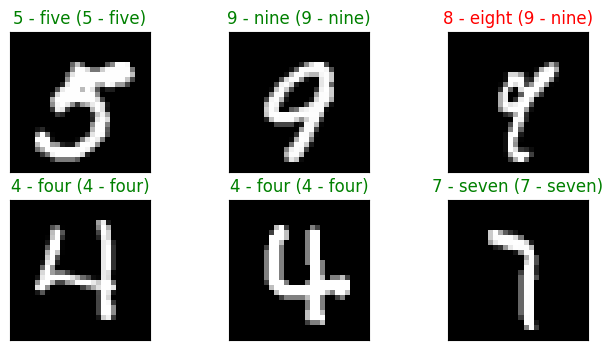

In [88]:
model.eval()
with torch.no_grad():
  x_batch, y_batch = next(iter(test_DL))
  x_batch = x_batch.to(DEVICE)
  y_hat = model(x_batch)
  pred = y_hat.argmax(dim=1)

x_batch = x_batch.to('cpu')

plt.figure(figsize=(8,4))
for idx in range(6):
  plt.subplot(2, 3, idx+1, xticks=[], yticks=[])
  plt.imshow(x_batch[idx].permute(1,2,0), cmap='gray')
  pred_class = test_DL.dataset.classes[pred[idx]]
  true_class = test_DL.dataset.classes[y_batch[idx]]
  plt.title(f'{pred_class} ({true_class})',
            color='g' if pred_class == true_class else 'r')